# CS240 Lab 8 - Q2

This notebook implements the four CIFAR-10 CNN experiments asked in the lab:

1. Model 1: Shallow CNN
2. Model 2: Shallow CNN + Batch Normalization
3. Model 3: Deeper CNN without skip connections
4. Model 4: Deep CNN with Residual Connections

The notebook includes:

- CIFAR-10 loading and preprocessing
- Training and validation loops
- Accuracy/loss plots
- A final comparison table
- Short conceptual answers for the discussion questions

Run this notebook on Colab/Kaggle or any machine with PyTorch and (preferably) a GPU.

In [1]:
import copy
import random
from dataclasses import dataclass

import matplotlib.pyplot as plt
import numpy as np
import torch
import torch.nn as nn
import torch.optim as optim
from torch.utils.data import DataLoader, random_split
from torchvision import datasets, transforms

try:
    import pandas as pd
except ImportError:
    pd = None

SEED = 240
random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)
torch.cuda.manual_seed_all(SEED)

device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
print('Device:', device)

Device: cpu


In [2]:
@dataclass
class Config:
    batch_size: int = 128
    epochs: int = 15
    lr: float = 1e-3
    weight_decay: float = 1e-4
    num_workers: int = 2
    valid_ratio: float = 0.1
    data_root: str = './data'


cfg = Config()

## Data Loading and Preprocessing

We use:

- normalization for stable training
- random crop and horizontal flip for data augmentation
- a train/validation split from the original training set

In [3]:
CIFAR10_MEAN = (0.4914, 0.4822, 0.4465)
CIFAR10_STD = (0.2470, 0.2435, 0.2616)

train_transform = transforms.Compose([
    transforms.RandomCrop(32, padding=4),
    transforms.RandomHorizontalFlip(),
    transforms.ToTensor(),
    transforms.Normalize(CIFAR10_MEAN, CIFAR10_STD),
])

eval_transform = transforms.Compose([
    transforms.ToTensor(),
    transforms.Normalize(CIFAR10_MEAN, CIFAR10_STD),
])

# Use the same split indices for both augmented-train and clean-validation datasets.
full_train_plain = datasets.CIFAR10(root=cfg.data_root, train=True, download=True, transform=eval_transform)
full_train_aug = datasets.CIFAR10(root=cfg.data_root, train=True, download=True, transform=train_transform)
test_dataset = datasets.CIFAR10(root=cfg.data_root, train=False, download=True, transform=eval_transform)

num_train = len(full_train_plain)
num_valid = int(cfg.valid_ratio * num_train)
num_subtrain = num_train - num_valid

generator = torch.Generator().manual_seed(SEED)
subtrain_plain, valid_dataset = random_split(full_train_plain, [num_subtrain, num_valid], generator=generator)
generator = torch.Generator().manual_seed(SEED)
train_dataset, _ = random_split(full_train_aug, [num_subtrain, num_valid], generator=generator)

train_loader = DataLoader(train_dataset, batch_size=cfg.batch_size, shuffle=True, num_workers=cfg.num_workers, pin_memory=True)
valid_loader = DataLoader(valid_dataset, batch_size=cfg.batch_size, shuffle=False, num_workers=cfg.num_workers, pin_memory=True)
test_loader = DataLoader(test_dataset, batch_size=cfg.batch_size, shuffle=False, num_workers=cfg.num_workers, pin_memory=True)

classes = test_dataset.classes
print('Train:', len(train_dataset), 'Validation:', len(valid_dataset), 'Test:', len(test_dataset))
print('Classes:', classes)

100%|███████████████████████████████████████████████████████████████████████████████████████████████████| 170M/170M [00:16<00:00, 10.4MB/s]


Train: 45000 Validation: 5000 Test: 10000
Classes: ['airplane', 'automobile', 'bird', 'cat', 'deer', 'dog', 'frog', 'horse', 'ship', 'truck']


/home/suhas/.venvs/common/lib/python3.13/site-packages/torch/utils/data/dataloader.py:1118: UserWarning: 'pin_memory' argument is set as true but no accelerator is found, then device pinned memory won't be used.
  super().__init__(loader)


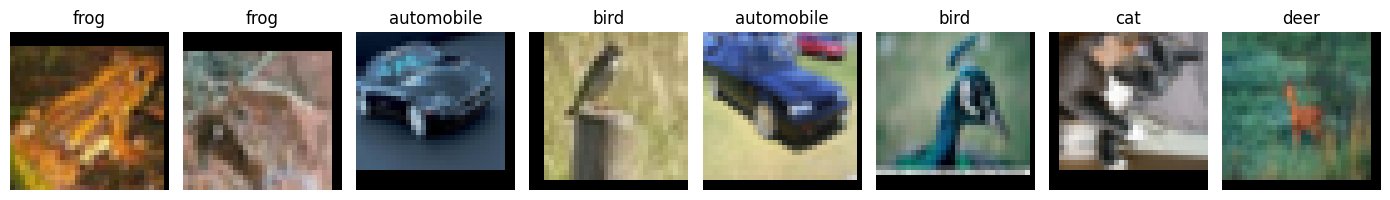

In [4]:
def show_batch(loader, classes, max_images=8):
    images, labels = next(iter(loader))
    images = images[:max_images]
    labels = labels[:max_images]

    mean = torch.tensor(CIFAR10_MEAN).view(3, 1, 1)
    std = torch.tensor(CIFAR10_STD).view(3, 1, 1)
    images = images * std + mean
    images = images.clamp(0, 1)

    plt.figure(figsize=(14, 3))
    for i in range(len(images)):
        plt.subplot(1, len(images), i + 1)
        plt.imshow(images[i].permute(1, 2, 0))
        plt.title(classes[labels[i].item()])
        plt.axis('off')
    plt.tight_layout()


show_batch(train_loader, classes)

## Model Definitions

In [5]:
class BaselineCNN(nn.Module):
    def __init__(self):
        super().__init__()
        self.features = nn.Sequential(
            nn.Conv2d(3, 32, kernel_size=3, padding=1),
            nn.ReLU(inplace=True),
            nn.MaxPool2d(2),
            nn.Conv2d(32, 64, kernel_size=3, padding=1),
            nn.ReLU(inplace=True),
            nn.MaxPool2d(2),
        )
        self.classifier = nn.Sequential(
            nn.Flatten(),
            nn.Linear(64 * 8 * 8, 256),
            nn.ReLU(inplace=True),
            nn.Dropout(0.3),
            nn.Linear(256, 10),
        )

    def forward(self, x):
        x = self.features(x)
        return self.classifier(x)


class BaselineCNNBN(nn.Module):
    def __init__(self):
        super().__init__()
        self.features = nn.Sequential(
            nn.Conv2d(3, 32, kernel_size=3, padding=1),
            nn.BatchNorm2d(32),
            nn.ReLU(inplace=True),
            nn.MaxPool2d(2),
            nn.Conv2d(32, 64, kernel_size=3, padding=1),
            nn.BatchNorm2d(64),
            nn.ReLU(inplace=True),
            nn.MaxPool2d(2),
        )
        self.classifier = nn.Sequential(
            nn.Flatten(),
            nn.Linear(64 * 8 * 8, 256),
            nn.ReLU(inplace=True),
            nn.Dropout(0.3),
            nn.Linear(256, 10),
        )

    def forward(self, x):
        x = self.features(x)
        return self.classifier(x)


def conv_block(in_channels, out_channels, use_bn=True, pool=False, dropout=0.0):
    layers = [nn.Conv2d(in_channels, out_channels, kernel_size=3, padding=1)]
    if use_bn:
        layers.append(nn.BatchNorm2d(out_channels))
    layers.append(nn.ReLU(inplace=True))
    if pool:
        layers.append(nn.MaxPool2d(2))
    if dropout > 0:
        layers.append(nn.Dropout2d(dropout))
    return layers


class DeepCNN(nn.Module):
    def __init__(self):
        super().__init__()
        self.features = nn.Sequential(
            *conv_block(3, 64, use_bn=True),
            *conv_block(64, 64, use_bn=True, pool=True),
            *conv_block(64, 128, use_bn=True),
            *conv_block(128, 128, use_bn=True, pool=True),
            *conv_block(128, 256, use_bn=True),
            *conv_block(256, 256, use_bn=True, pool=True, dropout=0.1),
        )
        self.classifier = nn.Sequential(
            nn.Flatten(),
            nn.Linear(256 * 4 * 4, 512),
            nn.ReLU(inplace=True),
            nn.Dropout(0.4),
            nn.Linear(512, 10),
        )

    def forward(self, x):
        x = self.features(x)
        return self.classifier(x)


class ResidualBlock(nn.Module):
    def __init__(self, in_channels, out_channels, stride=1):
        super().__init__()
        self.block = nn.Sequential(
            nn.Conv2d(in_channels, out_channels, kernel_size=3, stride=stride, padding=1, bias=False),
            nn.BatchNorm2d(out_channels),
            nn.ReLU(inplace=True),
            nn.Conv2d(out_channels, out_channels, kernel_size=3, stride=1, padding=1, bias=False),
            nn.BatchNorm2d(out_channels),
        )
        if stride != 1 or in_channels != out_channels:
            self.shortcut = nn.Sequential(
                nn.Conv2d(in_channels, out_channels, kernel_size=1, stride=stride, bias=False),
                nn.BatchNorm2d(out_channels),
            )
        else:
            self.shortcut = nn.Identity()
        self.relu = nn.ReLU(inplace=True)

    def forward(self, x):
        out = self.block(x)
        out = out + self.shortcut(x)
        return self.relu(out)


class SmallResNet(nn.Module):
    def __init__(self, num_classes=10):
        super().__init__()
        self.stem = nn.Sequential(
            nn.Conv2d(3, 64, kernel_size=3, stride=1, padding=1, bias=False),
            nn.BatchNorm2d(64),
            nn.ReLU(inplace=True),
        )
        self.layer1 = nn.Sequential(
            ResidualBlock(64, 64),
            ResidualBlock(64, 64),
        )
        self.layer2 = nn.Sequential(
            ResidualBlock(64, 128, stride=2),
            ResidualBlock(128, 128),
        )
        self.layer3 = nn.Sequential(
            ResidualBlock(128, 256, stride=2),
            ResidualBlock(256, 256),
        )
        self.pool = nn.AdaptiveAvgPool2d((1, 1))
        self.fc = nn.Linear(256, num_classes)

    def forward(self, x):
        x = self.stem(x)
        x = self.layer1(x)
        x = self.layer2(x)
        x = self.layer3(x)
        x = self.pool(x)
        x = torch.flatten(x, 1)
        return self.fc(x)

## Training Utilities

In [6]:
def accuracy_from_logits(logits, targets):
    preds = logits.argmax(dim=1)
    return (preds == targets).float().mean().item()


def run_epoch(model, loader, criterion, optimizer=None):
    training = optimizer is not None
    model.train(training)

    total_loss = 0.0
    total_correct = 0
    total_examples = 0

    for images, labels in loader:
        images = images.to(device)
        labels = labels.to(device)

        with torch.set_grad_enabled(training):
            logits = model(images)
            loss = criterion(logits, labels)

            if training:
                optimizer.zero_grad()
                loss.backward()
                optimizer.step()

        total_loss += loss.item() * images.size(0)
        total_correct += (logits.argmax(dim=1) == labels).sum().item()
        total_examples += images.size(0)

    return total_loss / total_examples, total_correct / total_examples


def evaluate(model, loader, criterion):
    return run_epoch(model, loader, criterion, optimizer=None)


def train_model(model, train_loader, valid_loader, epochs=10, lr=1e-3, weight_decay=1e-4):
    model = model.to(device)
    criterion = nn.CrossEntropyLoss()
    optimizer = optim.Adam(model.parameters(), lr=lr, weight_decay=weight_decay)

    history = {
        'train_loss': [],
        'train_acc': [],
        'valid_loss': [],
        'valid_acc': [],
    }

    best_state = None
    best_valid_acc = -1.0

    for epoch in range(1, epochs + 1):
        train_loss, train_acc = run_epoch(model, train_loader, criterion, optimizer)
        valid_loss, valid_acc = evaluate(model, valid_loader, criterion)

        history['train_loss'].append(train_loss)
        history['train_acc'].append(train_acc)
        history['valid_loss'].append(valid_loss)
        history['valid_acc'].append(valid_acc)

        if valid_acc > best_valid_acc:
            best_valid_acc = valid_acc
            best_state = copy.deepcopy(model.state_dict())

        print(
            f'Epoch {epoch:02d}/{epochs} | '
            f'train_loss={train_loss:.4f} train_acc={train_acc:.4f} | '
            f'valid_loss={valid_loss:.4f} valid_acc={valid_acc:.4f}'
        )

    if best_state is not None:
        model.load_state_dict(best_state)

    test_loss, test_acc = evaluate(model, test_loader, criterion)
    print(f'Test loss={test_loss:.4f} | Test acc={test_acc:.4f}')

    return model, history, test_loss, test_acc

In [7]:
def plot_history(history, title):
    epochs = range(1, len(history['train_loss']) + 1)

    plt.figure(figsize=(12, 4))

    plt.subplot(1, 2, 1)
    plt.plot(epochs, history['train_loss'], label='Train Loss')
    plt.plot(epochs, history['valid_loss'], label='Validation Loss')
    plt.xlabel('Epoch')
    plt.ylabel('Loss')
    plt.title(f'{title} - Loss')
    plt.legend()

    plt.subplot(1, 2, 2)
    plt.plot(epochs, history['train_acc'], label='Train Accuracy')
    plt.plot(epochs, history['valid_acc'], label='Validation Accuracy')
    plt.xlabel('Epoch')
    plt.ylabel('Accuracy')
    plt.title(f'{title} - Accuracy')
    plt.legend()

    plt.tight_layout()


def compare_histories(results):
    plt.figure(figsize=(12, 4))

    plt.subplot(1, 2, 1)
    for name, result in results.items():
        plt.plot(result['history']['valid_loss'], label=name)
    plt.xlabel('Epoch')
    plt.ylabel('Validation Loss')
    plt.title('Validation Loss Comparison')
    plt.legend()

    plt.subplot(1, 2, 2)
    for name, result in results.items():
        plt.plot(result['history']['valid_acc'], label=name)
    plt.xlabel('Epoch')
    plt.ylabel('Validation Accuracy')
    plt.title('Validation Accuracy Comparison')
    plt.legend()

    plt.tight_layout()

## Run Experiments

This cell trains all four models one after another. If runtime is limited, you can reduce `cfg.epochs` or train only a subset first.


Model 1 - Baseline CNN
Epoch 01/15 | train_loss=1.6278 train_acc=0.4054 | valid_loss=1.2849 valid_acc=0.5374
Epoch 02/15 | train_loss=1.3206 train_acc=0.5225 | valid_loss=1.1055 valid_acc=0.6056
Epoch 03/15 | train_loss=1.1771 train_acc=0.5769 | valid_loss=1.0001 valid_acc=0.6444
Epoch 04/15 | train_loss=1.0959 train_acc=0.6128 | valid_loss=0.9193 valid_acc=0.6778
Epoch 05/15 | train_loss=1.0450 train_acc=0.6311 | valid_loss=0.8790 valid_acc=0.6884
Epoch 06/15 | train_loss=0.9947 train_acc=0.6508 | valid_loss=0.8312 valid_acc=0.7060
Epoch 07/15 | train_loss=0.9588 train_acc=0.6614 | valid_loss=0.8206 valid_acc=0.7108
Epoch 08/15 | train_loss=0.9245 train_acc=0.6732 | valid_loss=0.7864 valid_acc=0.7284
Epoch 09/15 | train_loss=0.9029 train_acc=0.6835 | valid_loss=0.7768 valid_acc=0.7284
Epoch 10/15 | train_loss=0.8777 train_acc=0.6924 | valid_loss=0.7452 valid_acc=0.7376
Epoch 11/15 | train_loss=0.8584 train_acc=0.6988 | valid_loss=0.7648 valid_acc=0.7354
Epoch 12/15 | train_loss=0.840

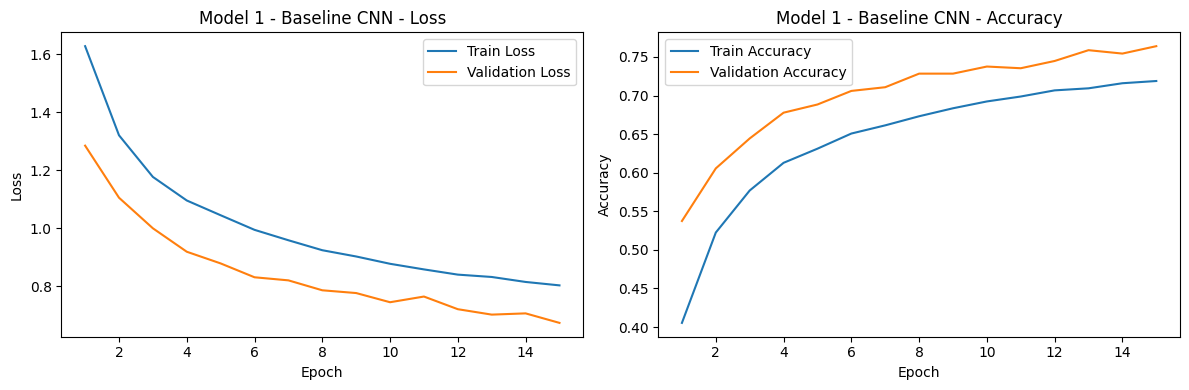


Model 2 - Baseline CNN + BN
Epoch 01/15 | train_loss=1.6480 train_acc=0.3966 | valid_loss=1.2539 valid_acc=0.5446
Epoch 02/15 | train_loss=1.3549 train_acc=0.5067 | valid_loss=1.2042 valid_acc=0.5562
Epoch 03/15 | train_loss=1.2514 train_acc=0.5513 | valid_loss=1.0066 valid_acc=0.6376
Epoch 04/15 | train_loss=1.1919 train_acc=0.5736 | valid_loss=0.9736 valid_acc=0.6600
Epoch 05/15 | train_loss=1.1459 train_acc=0.5934 | valid_loss=0.9529 valid_acc=0.6682
Epoch 06/15 | train_loss=1.1128 train_acc=0.6050 | valid_loss=0.8918 valid_acc=0.6876
Epoch 07/15 | train_loss=1.0860 train_acc=0.6148 | valid_loss=0.8855 valid_acc=0.6878
Epoch 08/15 | train_loss=1.0571 train_acc=0.6256 | valid_loss=0.8658 valid_acc=0.6924
Epoch 09/15 | train_loss=1.0417 train_acc=0.6327 | valid_loss=0.8615 valid_acc=0.6986
Epoch 10/15 | train_loss=1.0136 train_acc=0.6428 | valid_loss=0.8090 valid_acc=0.7118
Epoch 11/15 | train_loss=1.0019 train_acc=0.6479 | valid_loss=0.8064 valid_acc=0.7144
Epoch 12/15 | train_loss=

KeyboardInterrupt: 

In [8]:
model_builders = {
    'Model 1 - Baseline CNN': BaselineCNN,
    'Model 2 - Baseline CNN + BN': BaselineCNNBN,
    'Model 3 - Deep CNN': DeepCNN,
    'Model 4 - Small ResNet': SmallResNet,
}

results = {}

for name, builder in model_builders.items():
    print('\n' + '=' * 80)
    print(name)
    print('=' * 80)

    model = builder()
    trained_model, history, test_loss, test_acc = train_model(
        model,
        train_loader,
        valid_loader,
        epochs=cfg.epochs,
        lr=cfg.lr,
        weight_decay=cfg.weight_decay,
    )

    results[name] = {
        'model': trained_model,
        'history': history,
        'test_loss': test_loss,
        'test_acc': test_acc,
    }

    plot_history(history, name)
    plt.show()

In [ ]:
compare_histories(results)
plt.show()

summary_rows = []
for name, result in results.items():
    history = result['history']
    summary_rows.append({
        'model': name,
        'best_valid_acc': max(history['valid_acc']),
        'final_train_acc': history['train_acc'][-1],
        'final_valid_acc': history['valid_acc'][-1],
        'test_acc': result['test_acc'],
    })

if pd is not None:
    summary_df = pd.DataFrame(summary_rows).sort_values('test_acc', ascending=False)
    display(summary_df)
else:
    for row in sorted(summary_rows, key=lambda x: x['test_acc'], reverse=True):
        print(row)

## Observations Template

Fill this section after running the notebook:

- **Model 1:** Observe whether it underfits CIFAR-10 and how quickly validation accuracy saturates.
- **Model 2:** Compare with Model 1. BatchNorm usually improves stability, speeds up convergence, and can slightly improve final accuracy.
- **Model 3:** Check whether extra depth improves representation power but also makes optimization harder or increases overfitting.
- **Model 4:** Compare with Model 3. Residual connections usually make deeper training smoother and improve final performance.

Typical things to mention in your write-up:

- whether train loss decreases smoothly
- whether validation accuracy plateaus early
- whether there is a large train/validation gap
- which model gives the best test accuracy

## Answers to Comparison Questions

**1. How much does Batch Normalization help?**

Batch Normalization usually helps in two ways: it makes optimization more stable and it often speeds up convergence. In practice, the model with BatchNorm tends to reach a higher validation accuracy earlier than the plain baseline, and its loss curve is usually smoother. It can also act as a mild regularizer.

**2. Why does a plain deeper network sometimes perform worse?**

A deeper network has more representation power, but it is also harder to optimize. Gradients can weaken or training can become unstable, so even though the model is more expressive, gradient descent may fail to find good parameters. This is why simply stacking more layers does not always improve validation or test performance.

**3. How do skip connections help in training deeper networks?**

Skip connections create a direct path for information and gradients to flow through the network. Instead of learning a full mapping from scratch, each residual block only needs to learn a correction on top of the identity mapping. This reduces optimization difficulty, helps prevent degradation in deeper models, and usually leads to better training stability and accuracy.

**4. Signs of underfitting, overfitting, and optimization issues**

- **Underfitting:** both training and validation accuracy remain low.
- **Overfitting:** training accuracy becomes high, but validation accuracy stops improving or starts dropping.
- **Optimization issues:** loss fluctuates strongly, decreases very slowly, or gets stuck early despite sufficient model capacity.

## Optional Extensions

If you want stronger results, you can try:

- training for more epochs
- using SGD with momentum after the Adam baseline
- adding a learning-rate scheduler
- increasing width or using a larger ResNet-style model